# Do prefix associations survive a separate series partition?

**Level:** 3. **Prerequisites:** Earlier lessons in this topic; NumPy arrays and temporal evaluation. **Reading time:** 50 minutes.

**Question:** Which diagnostic associations survive a discovery/confirmation split, and does a feature-based method selector reduce error on the confirmation series? We examine the complete M4 Daily study under its fixed protocol. This lesson distinguishes three pieces of evidence: association tests, a learned selection rule and a future-informed oracle. A strong answer to one does not automatically answer the others, and a negative selection result must remain visible even when several feature tests reject their null hypotheses.

## Objectives

Trace prefix-only features through disjoint series partitions, repeat dependent-test correction and retrain the fixed selector. Separate an association result from the held-out error of a usable selection rule.

## Setup

Install the pinned environment below and read the compact executed corpus artifact. It contains per-series features, model scores, origin indices and partition identities, rather than the full downloaded observations. The producer's external forecast-path audit independently rescored every method at every origin before exporting these rows. Here we can repeat the statistical analysis and selector training from the same admitted feature/score table without downloading the raw benchmark or representing cached predictions as fresh model fits.

pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1
pip install preqts==0.3.0
pip install forecastscope==0.1.4


In [1]:
# Configure a portable session and suppress only the known repeated-shape control warning.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from scipy import stats
import stumpy
from engine.analysis.atlas import study_summary
from engine.analysis.sequence import matrix_profile, sequence_report
from engine.analysis.sequence import multiscale_entropy, time_reversal
from engine.analysis.atlas import prefix_features, associations, by_adjust
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-sequence-lessons"
warnings.filterwarnings("ignore", message="A large number of values in.*", category=UserWarning)
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "stumpy", "antropy", "nolds", "pycatch22", "scikit-learn",
            "statsforecast", "lightgbm", "mlforecast", "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))

print("ForecastScope", importlib.metadata.version("forecastscope"))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
stumpy 1.14.1
antropy 0.2.2
nolds 0.6.3
pycatch22 0.4.5
scikit-learn 1.9.1
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0
ForecastScope 0.1.4


## Data

The corpus is M4 Daily from the Monash forecasting archive (https://doi.org/10.5281/zenodo.4656548, CC BY 4.0). The compact `data/derived/forecastability.json` records source filename m4_daily_dataset.zip and source SHA-256 0f07fc3b67a93be1865de7853e06d8ad212f1a8cb8436ba859920cfe5625d889. Each series row retains its disjoint partition, pre-target features and per-method errors averaged over three origins; the fixed horizon is 14 and seasonal lag one. Fitting the selector from these rows is a new selector fit, not a repeat of the original forecast generation. The separately loaded BRKV values illustrate feature extraction only: they are synthetic seed-42 MIT controls, not M4 observations.


In [2]:
# Read the complete admitted feature and error table with its series partitions.
analysis = json.loads((root / "data/derived/BRKV_level_shift/analysis.json").read_text(encoding="utf-8"))
values = np.array(analysis["sequence"]["values"], dtype=float)
print("Original observations:", len(values))
study = json.loads((root / "data/derived/forecastability.json").read_text(encoding="utf-8"))
discovery = [r for r in study["series"] if r["partition"] == "discovery"]
confirmation = [r for r in study["series"] if r["partition"] == "confirmation"]
print("Source series:", study["source_n"])
print("Admitted series:", study["included_n"])
print("Origins per series:", study["protocol"]["origins"])
print("Discovery/confirmation:", len(discovery), len(confirmation))


Original observations: 300
Source series: 4227
Admitted series: 4226
Origins per series: 3
Discovery/confirmation: 2946 1280


## Method

The source contains 4,227 daily series. Each admitted sequence contributes three non-overlapping fourteen-step blocks, and each fit uses at most 1,024 preceding contiguous observations. Features are calculated once at the earliest origin, so none of those three future blocks enters their calculation. Daily forecast seasonality is one. A separately named weekly diagnostic does not change that forecast setting. Exact whole-sequence duplicates retain one identity for inference; excluded series remain listed with their reasons.


In [3]:
# Extract features before all three held-out target blocks in the worked case.
features = prefix_features(values[:-42])
print("Features available before the three final blocks:", len(features))
print("Earliest prefix observations:", features["history_length"])


Features available before the three final blocks: 40
Earliest prefix observations: 258.0


The displayed prefix call illustrates the same feature boundary on a committed case whose original observations are available locally. Its forty features combine compact statistical summaries with sequence ordering diagnostics. This example is not a replacement M4 row and does not claim to reconstruct the raw corpus from its compact output. In the actual study, each M4 feature vector came from that source series' own earliest fitting prefix, and its identity is bound to the external source file.

The analysis target is log(1 + the best mean MASE among the fixed eight-method roster). Each model's error is averaged across a series' three origins before choosing that within-roster minimum. This is an optimistic target, because future outcomes identify the winner. It describes achievable error among those specific configured methods, rather than inherent predictability. A feature can also associate with how the MASE denominator is constructed, without revealing a useful physical forecasting mechanism.


In [4]:
# Repeat all preregistered feature tests in each disjoint series partition.
discovery_tests = associations(discovery)
confirmation_tests = associations(confirmation)
print("Hypotheses per partition:", len(discovery_tests))
print("Rejected in discovery:", sum(r["rejected"] for r in discovery_tests))
print("Rejected in confirmation:", sum(r["rejected"] for r in confirmation_tests))


Hypotheses per partition: 40
Rejected in discovery: 25
Rejected in confirmation: 21


Discovery and confirmation series are disjoint by exact sequence identity. Their allocation is deterministic and independent of the error labels. We test every preregistered feature in each partition, retaining sample counts, signed Kendall effects and probabilities. The unit is a series, not each origin treated as an independent replication. Aggregating origins addresses that immediate pseudoreplication risk; it does not prove that different benchmark series are independent in their underlying industries or sources.

## Comparison


In [5]:
# Check the chosen confirmation association against SciPy Kendall tau.
chosen = "linear_trend_r"
pairs = [(r["features"][chosen], np.log1p(min(r["mase"].values())))
         for r in confirmation if r["features"][chosen] is not None]
x, y = zip(*pairs)
tau, probability = stats.kendalltau(x, y)
print("Reference feature:", chosen)
print("Kendall tau:", round(float(tau), 6))
print("Reference probability:", float(probability))


Reference feature: linear_trend_r
Kendall tau: 0.147041
Reference probability: 3.2664554785751826e-15


The direct SciPy calculation checks one explicitly selected feature against the reference Kendall implementation. It uses the confirmation rows with available feature values and the same log-transformed target. The coefficient measures a monotonic association, not a fitted causal response. Ties are handled by the library. A small probability must still be interpreted within the complete feature family, rather than reported alone because that feature happened to look interesting.


In [6]:
# Compare dependent-test BY adjustment with the reference implementation.
probabilities = [r["p"] for r in confirmation_tests]
corrected = by_adjust(probabilities)
library = stats.false_discovery_control(probabilities, method="by")
print("Maximum BY reference difference:", f"{np.max(np.abs(corrected-library)):.8f}")
print("Confirmation threshold:", study["protocol"]["q"])


Maximum BY reference difference: 0.00000000
Confirmation threshold: 0.05


BY correction uses the number of tests and its harmonic factor to account for dependent feature hypotheses. We compare the product's adjusted probabilities with the reference calculation over the entire confirmation family. A confirmation requires corrected rejection in both partitions and the same direction of effect. Selecting only the small probabilities before correcting would define a different and misleading procedure. Neither correction removes unmeasured dependence between related benchmark sources.


In [7]:
# Verify a prefix-only profile without admitting future observations.
same_prefix = values[:-42]
product_profile = matrix_profile(same_prefix, window=24)
library_profile = stumpy.stump(same_prefix, m=24)
print("Prefix-only profile difference:",
      f"{np.max(np.abs(np.asarray(product_profile['profile'])-library_profile.P_)):.8f}")


Prefix-only profile difference: 0.00000000


The exact profile reference call uses a prefix that stops before the three final blocks in the worked case. It verifies that the diagnostic adapter can operate inside the temporal boundary rather than needing the complete future sequence. The app's retrospective case profile and this prefix-only calculation therefore serve different purposes. Their window coordinates retain original observation units, but their eligible neighboring windows and resulting distances can differ because their available observations differ.


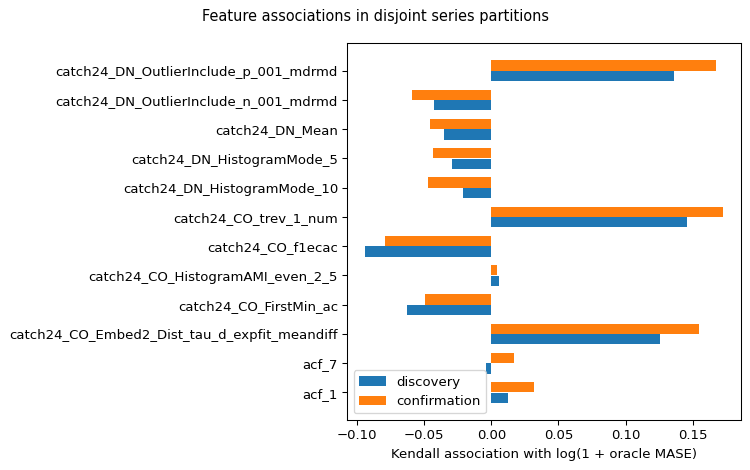

In [8]:
# Show the first twelve features in schema order rather than significance order.
chosen_tests = study["summary"]["associations"][:12]
fig, ax = plt.subplots(figsize=(8, 5))
locations = np.arange(len(chosen_tests))
ax.barh(locations-.18, [r["discovery"]["tau"] for r in chosen_tests], height=.35, label="discovery")
ax.barh(locations+.18, [r["confirmation"]["tau"] for r in chosen_tests], height=.35, label="confirmation")
ax.set_yticks(locations, [r["feature"] for r in chosen_tests])
ax.set(xlabel="Kendall association with log(1 + oracle MASE)")
ax.legend()
fig.suptitle('Feature associations in disjoint series partitions', fontsize=11)
fig.tight_layout()
plt.show()


The figure shows the first twelve features in the fixed schema order, not a selection made by their smallest probabilities. All forty tests remain in the artifact and in the app's corrected-results table. Compare direction and magnitude across partitions before reading a rejection flag. Similar coefficients across groups are useful conditional evidence, while opposite signs or disappearing effects should remain findings rather than be removed from the presentation.


In [9]:
# Train the fixed selector again using discovery rows and discovery-only imputation.
reproduced, trained_selector = study_summary(study["series"])
differences = [abs(reproduced["selection_mean_mase"][n]-study["summary"]["selection_mean_mase"][n])
               for n in reproduced["selection_mean_mase"]]
print("Maximum reproduced selection-score difference:", f"{max(differences):.8f}")
assert len(set(r["sequence_sha256"] for r in study["series"])) == study["included_n"]
assert not set(r["id"] for r in discovery) & set(r["id"] for r in confirmation)
assert np.allclose(corrected, library)
print("Duplicate, partition and corrected-probability checks passed")


Maximum reproduced selection-score difference: 0.00000000
Duplicate, partition and corrected-probability checks passed


The first table compares the independently called Kendall reference with the adapter's same-feature confirmation statistic. The second table contrasts the newly fitted selector, the discovery-chosen constant and the retrospective oracle on the confirmation series. Each contributes one mean over its three forecast origins; individual leads are not additional series. The oracle observes the future scoring outcome and is a lower bound, not an available forecast-selection rule.


In [10]:
# Tabulate the actually executed reference statistic and the newly fitted selector outcome.
adapter = next(row for row in confirmation_tests if row["feature"] == chosen)
print("| Implementation | Kendall tau | Probability |")
print("|---|---:|---:|")
print(f"| product adapter | {adapter['tau']:.8f} | {adapter['p']:.8g} |")
print(f"| SciPy reference | {float(tau):.8f} | {float(probability):.8g} |")
print("| Rule | Confirmation series | Mean MASE |")
print("|---|---:|---:|")
for rule, score in reproduced["selection_mean_mase"].items():
    print(f"| {rule} | {len(confirmation)} | {score:.6f} |")


| Implementation | Kendall tau | Probability |
|---|---:|---:|
| product adapter | 0.14704115 | 3.2664555e-15 |
| SciPy reference | 0.14704115 | 3.2664555e-15 |
| Rule | Confirmation series | Mean MASE |
|---|---:|---:|
| selected | 1280 | 3.350125 |
| discovery_constant | 1280 | 3.256977 |
| oracle | 1280 | 3.000478 |


Agreement between reference and adapter concerns a precisely matched statistic, not a forecast accuracy claim. The selector's table measures a different decision: whether features estimated before targets can choose a lower-error method on untouched series. Its unfavorable mean relative to the discovery constant remains visible. Confirmed association alone cannot justify replacing that constant with this selector, because association and useful out-of-sample selection are different hypotheses.


The selector is now fitted again from the compact discovery rows. It uses the fixed forest configuration and discovery-only missing-value medians. Confirmation labels do not choose hyperparameters, feature thresholds or the constant comparator. We compare the reproduced confirmation scores with the exported scores, so the following figure is based on an executed public-data-table training path. Repeating the selection calculation is distinct from refitting the eight forecasting methods on the full external corpus.


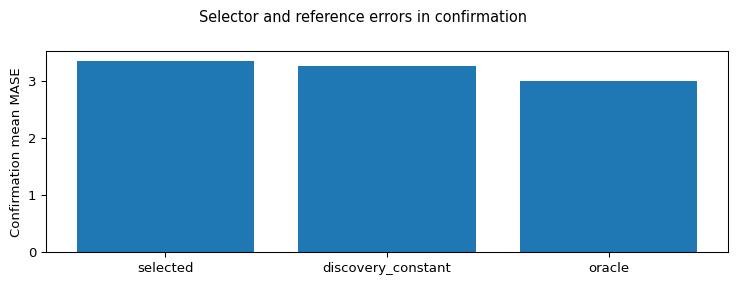

selected 3.3501
discovery_constant 3.257
oracle 3.0005


In [11]:
# Plot confirmation scores from the reproduced selection calculation.
scores = reproduced["selection_mean_mase"]
fig, ax = plt.subplots()
ax.bar(list(scores), list(scores.values()))
ax.set(ylabel="Confirmation mean MASE")
fig.suptitle('Selector and reference errors in confirmation', fontsize=11)
fig.tight_layout()
plt.show()
for name, score in scores.items():
    print(name, round(score, 4))


The oracle bar uses future scores to choose a different winner for every confirmation series. It is therefore a lower reference within this roster, not a deployable rule. The constant method was chosen from discovery only, and the forest makes its choices from available prefix features. Read both deployable rules against the same confirmation rows and units. A low oracle error can coexist with an unsuccessful learned selector because the features may not reliably identify the individual winners.

Answer: the reproduced selector has confirmation mean MASE 3.3501, compared with 3.2570 for the discovery-selected constant. 21 features satisfy the declared two-partition confirmation rule. These are different conclusions: feature association does not guarantee an improvement in discrete method selection, and an observed selection difference does not establish population superiority. The source count is 4,227 and the origin count is three, while the statistical sample consists of the admitted distinct series.

### Limitations

The corpus is one benchmark frequency with anonymized source identities. Exact deduplication cannot identify every related industry or common latent driver. The roster excludes deep and pretrained models and cannot rank them by implication. Context truncation, fixed fitting configurations and the use of a scaled-error oracle limit the target's meaning. No result is used to revise this study's feature set or forest settings. The separate twenty-two-variant case experiment remains available with its own package identities and provenance.

### Sensitivity to the performance summary

Let $\overline E_{i,k}$ be the mean MASE across the three reserved origins of series $i$ for method $k$. The rank association uses a transformed within-roster oracle.

$$
A_i=\log(1+\min_k \overline E_{i,k}).
$$

For the confirmation series, let $k_i$ denote the forest's choice made from prefix features and let $k_0$ denote the method selected by discovery mean MASE. The comparison of these two implementable policies uses

$$
\Delta_i=\overline E_{i,k_i}-\overline E_{i,k_0},
\qquad \overline\Delta=\frac{1}{N}\sum_{i=1}^{N}\Delta_i.
$$

The oracle takes the minimum after all scoring outcomes are available. The selector and the constant rule choose before those confirmation outcomes are used. Strong association with $A_i$ can arise because several methods have low errors on the same series. It does not tell the forest which specific method wins. The next figure shows the empirical cumulative distribution of the paired differences for the confirmation series. Each series supplies one number regardless of its history length.


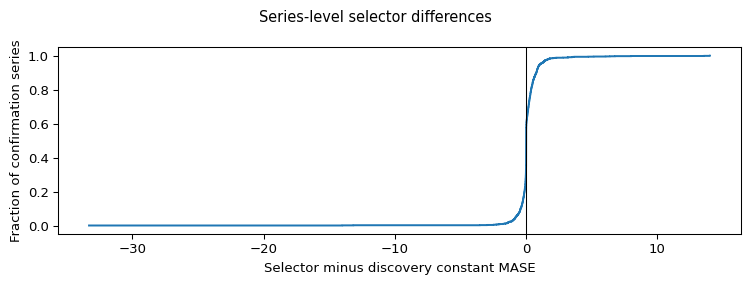

Lower, tied, higher: 599 24 657
Mean paired difference: 0.093148


In [12]:
# Inspect confirmation-series differences behind the aggregate selector score.
constant_name = reproduced["constant_method"]
paired = np.sort([row["mase"][row["selected_method"]] - row["mase"][constant_name]
                  for row in confirmation])
fig, ax = plt.subplots()
ax.step(paired, np.arange(1, len(paired) + 1) / len(paired), where="post")
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Selector minus discovery constant MASE", ylabel="Fraction of confirmation series")
fig.suptitle('Series-level selector differences', fontsize=11)
fig.tight_layout()
plt.show()
print("Lower, tied, higher:", int(sum(paired < 0)), int(sum(paired == 0)), int(sum(paired > 0)))
print("Mean paired difference:", round(float(paired.mean()), 6))


To read the distribution, locate zero. Values to its left favor the selector; values to its right favor the discovery constant. A jump at zero can occur because both rules choose the same method or because their scores tie. The mean can be driven by a tail of large differences, so compare it with the direction counts. These observations reuse the confirmation results and describe the fixed outcome. Do not use the plotted tails to remove difficult series, pick a new feature or tune the forest on the confirmation partition.

### Adapt the design to your own data

Identify groups that share an underlying process before creating the partition. For example, multiple channels from the same installation may be distinct sequences but still reveal a common regime. Keep related channels on one side of the split. Write down the rule for excluding short sequences and zero scales, and log every excluded identity. Define the forecast horizon and historical feature cutoff consistently so every row contains features known before every scored target.

Fit imputation, the baseline method choice and all selector settings on discovery data. For confirmation, use the fixed fitted pipeline and score both rules on identical series and origins. Compare paired differences and counts as in the figure. If a few extreme errors dominate the result, retain them and document their source. Use a different untouched group for any revised policy. This design can test method selection for a specified roster, frequency and population without pretending to measure an intrinsic limit of predictability.

### Reproduce


Run all cells and compare the reference corrections, reproduced selector scores and partition checks. Full forecasting reproduction additionally requires the licensed TSF and the external evaluator; the repository documents its source checksum, cache identity and independent path scoring. The compact notebook reproduces the inferential and selection layer and states that boundary explicitly.


## Results

**Answer:** The selector reaches 3.3501 mean MASE against 3.2570 for the discovery constant. The admitted counts, corrected feature decisions and confirmation selection errors below answer the fixed corpus question. A reproduced selector score verifies the table calculation; it does not turn a retrospective oracle into a forecasting policy or establish population superiority.

## Summary

The confirmation partition evaluates rules and hypotheses fixed elsewhere. Keep the complete corrected family, exclusions and negative selection outcomes beside any favorable coefficient.

## References

Monash M4 Daily, DOI 10.5281/zenodo.4656548. The tsfresh feature-filtering documentation explains dependent-test BY correction. Hyndman and Koehler, DOI 10.1016/j.ijforecast.2006.03.001, discuss the scaled-error interpretation. STUMPY documents the exact prefix profile used in the numerical comparison.

[Dependent-test feature filtering](https://tsfresh.readthedocs.io/en/v0.21.0/text/feature_filtering.html); [Matrix Profile reference](https://doi.org/10.1109/ICDM.2016.0179).

- https://doi.org/10.5281/zenodo.4656548

- https://doi.org/10.1016/j.ijforecast.2006.03.001
